In [9]:
import os
import json
import random
import numpy as np
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
PROJECT_DIR = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")
PROCESSED_DIR = PROJECT_DIR / "Processed_unprepared"
META_PATH = PROCESSED_DIR / "meta.json"

In [31]:
with open(META_PATH, "r") as f:
    meta = json.load(f)

CHANNEL_NAMES = meta["channels"]
N_CHANNELS = meta["n_channels"]
HEIGHT, WIDTH = meta["tensor_shape"][1], meta["tensor_shape"][2]

print("Channels:", CHANNEL_NAMES)
print("Number of channels:", N_CHANNELS)
print("Input shape:", (N_CHANNELS, HEIGHT, WIDTH))

Channels: ['log_mel', 'harmonic_mel', 'percussive_mel', 'delta', 'delta_delta', 'zcr', 'rms', 'spectral_centroid', 'spectral_rolloff', 'spectral_bandwidth', 'spectral_contrast', 'chroma', 'mfcc', 'tonnetz', 'spectral_flatness', 'f0', 'voiced_prob', 'spectral_flux', 'wide_band_mel', 'rms_periodicity']
Number of channels: 20
Input shape: (20, 128, 128)


In [15]:
CLASS_NAMES = ["choking", "laughter"]
NUM_CLASSES = len(CLASS_NAMES)

class_to_idx = {
    class_name: i for i, class_name in enumerate(CLASS_NAMES)
}

print(class_to_idx)

{'choking': 0, 'laughter': 1}


In [16]:
class AudioFeatureDataset(Dataset):
    def __init__(self, processed_dir, class_names):
        self.samples = []
        self.class_names = class_names

        for class_name in class_names:
            class_dir = Path(processed_dir) / class_name
            label = class_to_idx[class_name]

            files = list(class_dir.glob("*.npy"))

            for file_path in files:
                self.samples.append((file_path, label))

        random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]

        x = np.load(file_path).astype(np.float32)

        # shape should be (C, 128, 128)
        x = torch.tensor(x, dtype=torch.float32)
        y = torch.tensor(label, dtype=torch.long)

        return x, y

In [33]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import defaultdict
import re

CLASS_NAMES = ["choking", "laughter"]
SEED = 42

AUG_SUFFIXES = [
    "_noise",
    "_ts0.85",
    "_ts1.15",
    "_ps-2",
    "_ps+2",
]

def get_base_name(path):
    stem = path.stem
    for suffix in AUG_SUFFIXES:
        if stem.endswith(suffix):
            stem = stem[: -len(suffix)]
    return stem

# collect all files by original recording
groups = defaultdict(list)
group_labels = {}

for label_idx, cls in enumerate(CLASS_NAMES):
    cls_dir = PROCESSED_DIR / cls
    files = sorted(cls_dir.glob("*.npy"))

    for f in files:
        base = get_base_name(f)
        key = f"{cls}/{base}"

        groups[key].append(f)
        group_labels[key] = label_idx

print("Number of original recording groups:", len(groups))
print("Total npy files:", sum(len(v) for v in groups.values()))

group_keys = list(groups.keys())
labels = [group_labels[k] for k in group_keys]

train_keys, temp_keys, train_labels, temp_labels = train_test_split(
    group_keys,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_keys, test_keys, val_labels, test_labels = train_test_split(
    temp_keys,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

def is_augmented(path):
    stem = path.stem
    return any(stem.endswith(suffix) for suffix in AUG_SUFFIXES)

train_files = []
val_files = []
test_files = []

# Train gets originals + augmentations
for k in train_keys:
    train_files.extend(groups[k])

# Val/Test get originals only
for k in val_keys:
    originals = [f for f in groups[k] if not is_augmented(f)]
    val_files.extend(originals)

for k in test_keys:
    originals = [f for f in groups[k] if not is_augmented(f)]
    test_files.extend(originals)

print("Train files:", len(train_files))
print("Val files:", len(val_files))
print("Test files:", len(test_files))

train_bases = set(get_base_name(f) for f in train_files)
val_bases = set(get_base_name(f) for f in val_files)
test_bases = set(get_base_name(f) for f in test_files)

print("Train ∩ Val:", train_bases & val_bases)
print("Train ∩ Test:", train_bases & test_bases)
print("Val ∩ Test:", val_bases & test_bases)

assert len(train_bases & val_bases) == 0
assert len(train_bases & test_bases) == 0
assert len(val_bases & test_bases) == 0

print("No leakage detected.")

Number of original recording groups: 120
Total npy files: 720
Train files: 504
Val files: 18
Test files: 18
Train ∩ Val: set()
Train ∩ Test: set()
Val ∩ Test: set()
No leakage detected.


In [34]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [35]:
class AudioCNN(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(AudioCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [36]:
import torch # Added import to resolve NameError
import torch.nn as nn # Added import to resolve potential NameError for nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AudioCNN(
    in_channels=N_CHANNELS,
    num_classes=NUM_CLASSES
).to(device)

# 1. Weighted loss - הכי חשוב!
weights = torch.tensor([1.0, 3.0]).to(device)  # תני משקל גבוה ל-laughter
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0003333)

Using device: cuda


In [21]:
x, y = dataset[0]

print(x.shape)
print(y)
print(x.dtype)

NameError: name 'dataset' is not defined

In [37]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        outputs = model(x)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

        preds = torch.argmax(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * x.size(0)

            preds = torch.argmax(outputs, dim=1)

            correct += (preds == y).sum().item()
            total += y.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy, all_preds, all_labels

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AudioCNN(
    in_channels=N_CHANNELS,
    num_classes=NUM_CLASSES
).to(device)

# 1. Weighted loss - הכי חשוב!
weights = torch.tensor([1.0, 3.0]).to(device)  # תני משקל גבוה ל-laughter
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0003333)

Using device: cuda


In [38]:
from pathlib import Path # Added import for Path to define PROJECT_DIR

# Re-defining PROJECT_DIR to resolve NameError
PROJECT_DIR = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")

NUM_EPOCHS = 10 # Increased number of epochs as requested

train_losses = []
val_losses = []
train_accs = []
val_accs = []

# 2. Early stopping + יותר epochs
best_val_loss = float('inf')
patience = 5
counter = 0

# Define path for saving the best model
best_model_path = PROJECT_DIR / "best_audio_cnn_model.pth"

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    # Early stopping logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping!")
            break

# 3. טעני את המודל הכי טוב בסוף
print(f"Loading best model from {best_model_path}")
model.load_state_dict(torch.load(best_model_path))
print("Best model loaded.")

Epoch [1/10] Train Loss: 0.8121 | Train Acc: 0.6528 Val Loss: 0.6363 | Val Acc: 0.6667
Epoch [2/10] Train Loss: 0.3335 | Train Acc: 0.8373 Val Loss: 0.5119 | Val Acc: 0.7593
Epoch [3/10] Train Loss: 0.2283 | Train Acc: 0.9008 Val Loss: 0.6357 | Val Acc: 0.7500
Epoch [4/10] Train Loss: 0.1620 | Train Acc: 0.9365 Val Loss: 0.6748 | Val Acc: 0.8056
Epoch [5/10] Train Loss: 0.1354 | Train Acc: 0.9226 Val Loss: 0.4412 | Val Acc: 0.8333
Epoch [6/10] Train Loss: 0.1063 | Train Acc: 0.9524 Val Loss: 0.4586 | Val Acc: 0.7963
Epoch [7/10] Train Loss: 0.0542 | Train Acc: 0.9722 Val Loss: 0.4208 | Val Acc: 0.8333
Epoch [8/10] Train Loss: 0.0765 | Train Acc: 0.9663 Val Loss: 0.5594 | Val Acc: 0.8241
Epoch [9/10] Train Loss: 0.0739 | Train Acc: 0.9583 Val Loss: 0.4135 | Val Acc: 0.8333
Epoch [10/10] Train Loss: 0.0348 | Train Acc: 0.9881 Val Loss: 0.6232 | Val Acc: 0.8333
Loading best model from /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/best_audio_cnn_model.pth
Best model loaded.


In [ ]:
from pathlib import Path # Added import for Path to define PROJECT_DIR

# Re-defining PROJECT_DIR to resolve NameError
PROJECT_DIR = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")

NUM_EPOCHS = 5 # Increased number of epochs as requested

train_losses = []
val_losses = []
train_accs = []
val_accs = []

# 2. Early stopping + יותר epochs
best_val_loss = float('inf')
patience = 5
counter = 0

# Define path for saving the best model
best_model_path = PROJECT_DIR / "best_audio_cnn_model.pth"

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    # Early stopping logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping!")
            break

# 3. טעני את המודל הכי טוב בסוף
print(f"Loading best model from {best_model_path}")
model.load_state_dict(torch.load(best_model_path))
print("Best model loaded.")

Epoch [1/5] Train Loss: 0.0495 | Train Acc: 0.9784 Val Loss: 0.8864 | Val Acc: 0.7778
Epoch [2/5] Train Loss: 0.0945 | Train Acc: 0.9537 Val Loss: 0.7539 | Val Acc: 0.8056
Epoch [3/5] Train Loss: 0.1151 | Train Acc: 0.9444 Val Loss: 1.1958 | Val Acc: 0.7083
Epoch [4/5] Train Loss: 0.0400 | Train Acc: 0.9846 Val Loss: 0.7734 | Val Acc: 0.7778
Epoch [5/5] Train Loss: 0.0100 | Train Acc: 0.9938 Val Loss: 0.8618 | Val Acc: 0.7917
Loading best model from /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/best_audio_cnn_model.pth
Best model loaded.


In [39]:
test_loss, test_acc, test_preds, test_labels = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Test Loss: 0.4104790695181927
Test Accuracy: 0.8240740740740741


In [40]:
print(classification_report(
    test_labels,
    test_preds,
    target_names=CLASS_NAMES
))

              precision    recall  f1-score   support

     choking       0.77      0.98      0.86        60
    laughter       0.97      0.62      0.76        48

    accuracy                           0.82       108
   macro avg       0.87      0.80      0.81       108
weighted avg       0.86      0.82      0.82       108



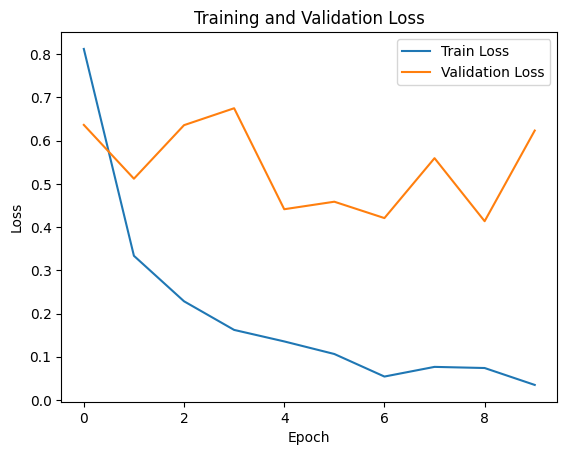

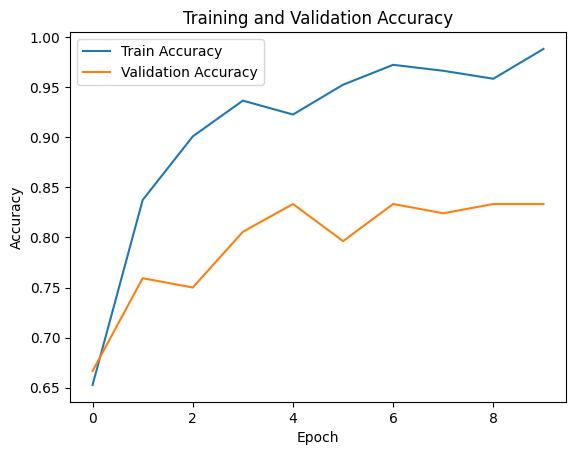

In [41]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training and Validation Loss")
plt.show()

plt.figure()
plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training and Validation Accuracy")
plt.show()

In [ ]:
test_loss, test_acc, test_preds, test_labels = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Test Loss: 0.6251762877735827
Test Accuracy: 0.6805555555555556


In [ ]:
print(classification_report(
    test_labels,
    test_preds,
    target_names=CLASS_NAMES
))

              precision    recall  f1-score   support

     choking       0.62      0.45      0.53        11
    laughter       0.67      0.94      0.78        49
       other       0.94      0.76      0.84        86

    accuracy                           0.79       146
   macro avg       0.74      0.72      0.71       146
weighted avg       0.83      0.79      0.80       146



[[59  1]
 [18 30]]


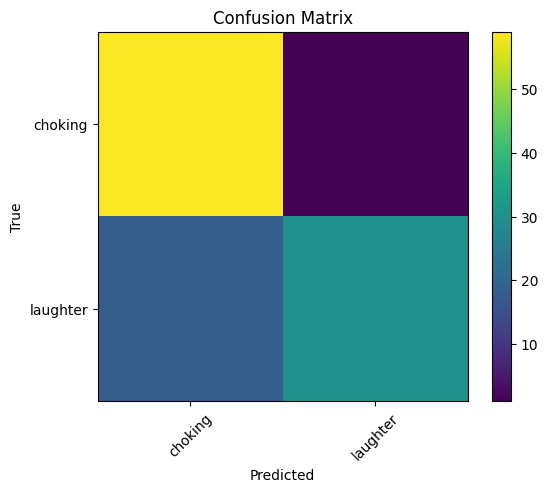

In [42]:
cm = confusion_matrix(test_labels, test_preds)

print(cm)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.colorbar()
plt.show()

In [ ]:
SAVE_PATH = PROJECT_DIR / "audio_cnn_model.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "channel_names": CHANNEL_NAMES,
    "n_channels": N_CHANNELS,
    "input_shape": (N_CHANNELS, HEIGHT, WIDTH)
}, SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Model saved to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/audio_cnn_model.pth
